# Workshop 3 —NOISE SPECTRUM DENSITY ESTIMATION AND WIENER FILTERING
 - **Student:** Francesc SERRA CRESPÍ
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [ ]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import periodogram, welch
from scipy.io.wavfile import write
from scipy.fft import irfft,rfft, rfftfreq
from scipy.stats import pearsonr


# 1. CLASS DEFINITION

We define the `signal_data` class, used throughout the previous workshops to efficiently store the main information associated with an audio signal.

Given a `.wav` file, the class automatically stores the **sampling rate**, **signal samples**, **sampling interval**, **number of samples**, **duration**, **time vector**, **Nyquist frequency**, and **frequency resolution**. This provides a common structure for handling both music and noise signals throughout the analysis.

In [2]:
class signal_data: # Class to store signal data
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length


# 2. DATA LOADING
We download both the original music signal and the noise signals that will be used throughout the analysis.

In [3]:
# Music 
audio_signal = signal_data('data/music.wav')
# Noise 1
noise1 = signal_data('data/noise/noise1.wav')
#Noise 2
noise2 = signal_data('data/noise/noise2.wav')
# Noise 3
noise3 = signal_data('data/noise/noise3.wav')

## 3. NOISE PSD ESTIMATION AND CLASSIFICATION

In this section, the different noise signals are analyzed using two **Power Spectral Density (PSD)** estimation methods. Since noise is random by nature, directly inspecting its FFT is usually not informative at all. Instead, analyzing how the signal power is distributed across frequencies reveals some characteristic in the spectral domain that can help identify the type of noise.

For this purpose, we use the **Periodogram** and **Welch's method**. Both are based on the same general idea. First, the signal is transformed from the time domain to the frequency domain using the **FFT**. The squared magnitude of each Fourier coefficient,

$$
|X[k]|^2,
$$

represents the contribution of that frequency component to the signal energy. After applying the appropriate normalization, this gives an estimate of the **Power Spectral Density (PSD)**, which describes how the power of the signal is distributed across frequency.

The main difference between the two methods is how this estimation is performed. The **Periodogram** computes a single PSD estimate using the entire signal. In contrast, **Welch's method** divides the signal into overlapping segments, computes a periodogram for each segment, and then averages these estimates. 


Moreover, expressing the PSD in the **dB domain** makes differences in spectral power easier to visualize. To further characterize the frequency dependence of the noise, the Welch PSD is also analyzed against a **logarithmic frequency axis**. In this representation, the spectral slope can be estimated from the relationship between $PSD_{dB}$ and $log_{10}(f)$. This slope provides a compact descriptor of the noise spectrum and is useful for noise classification.


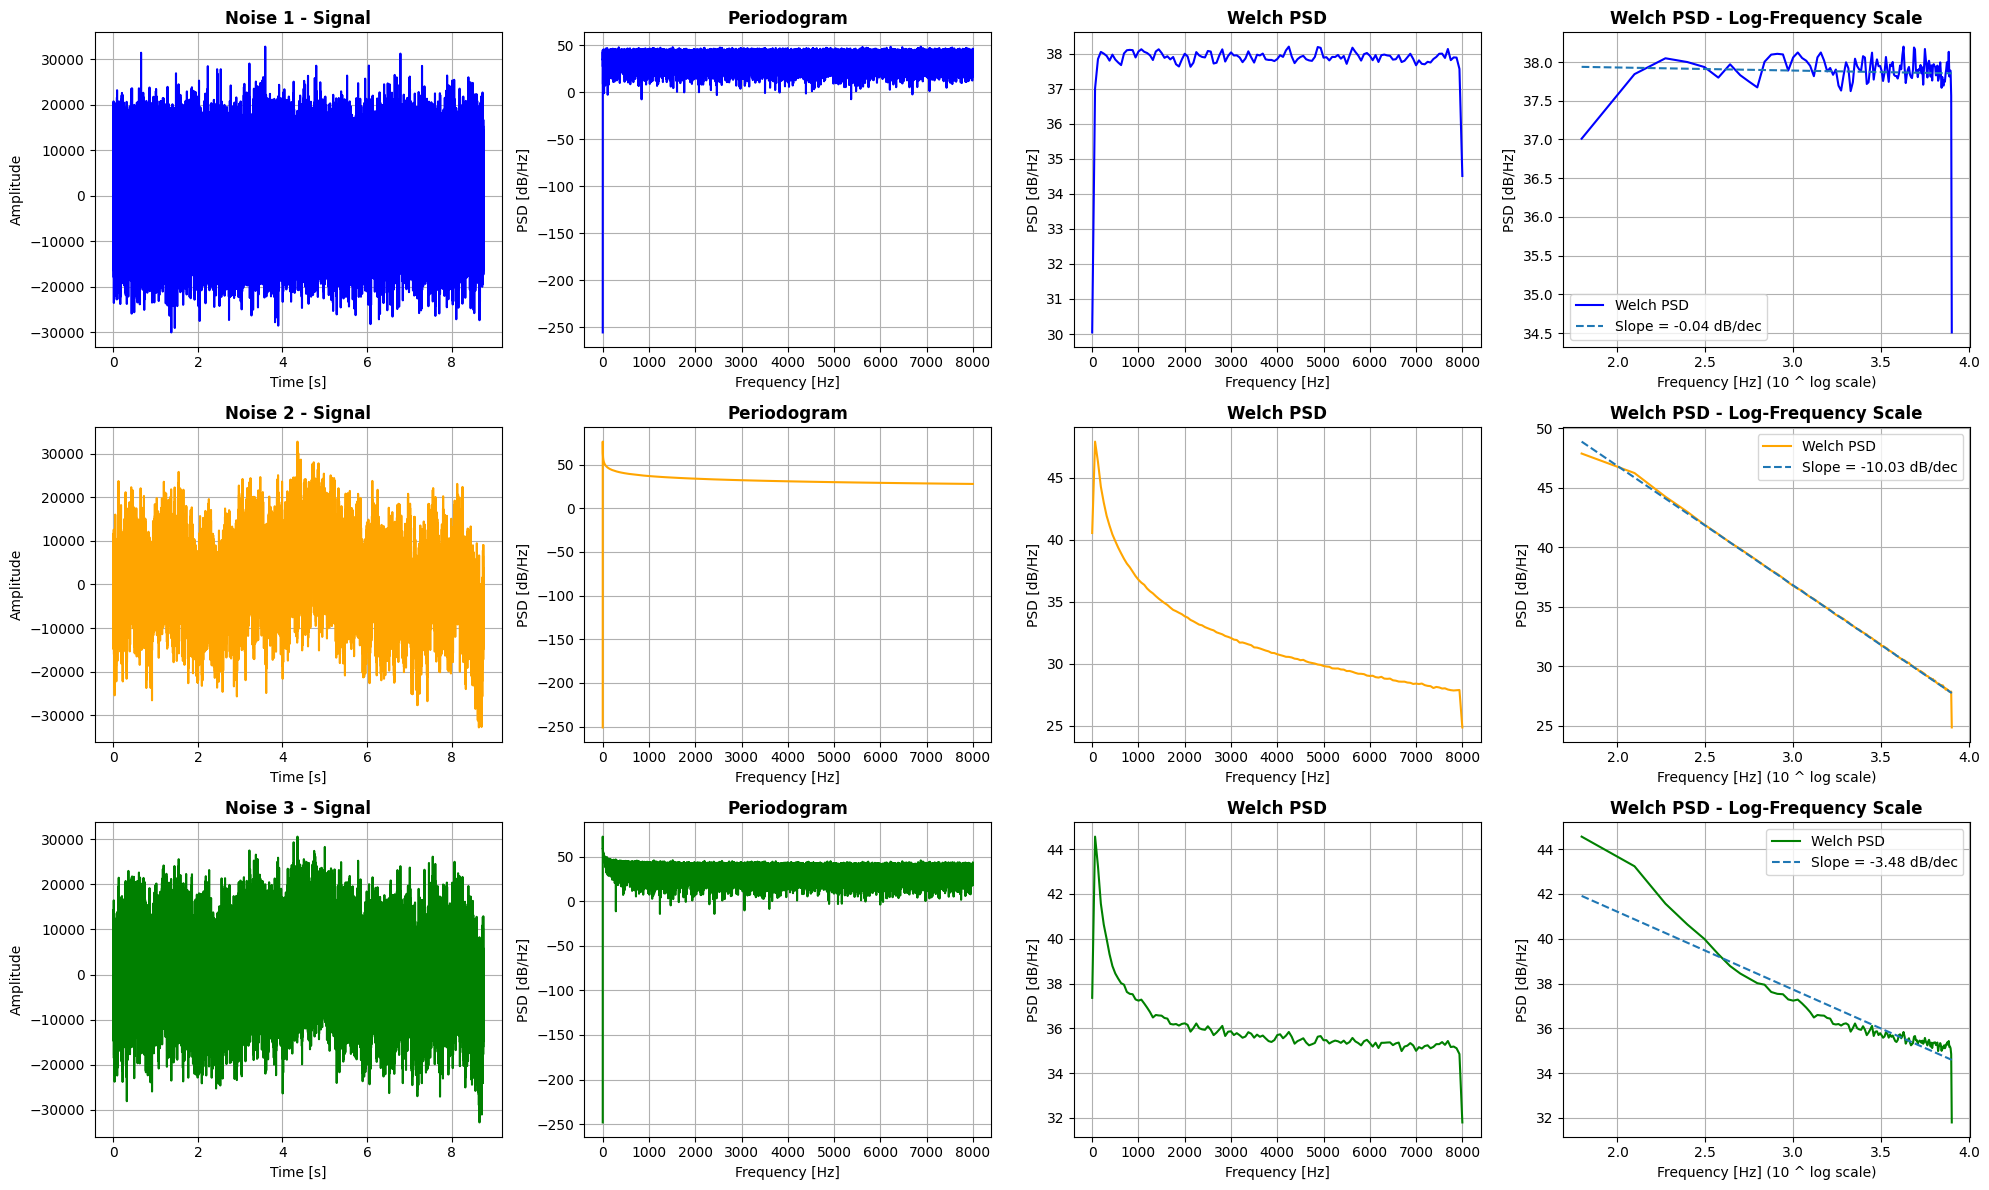

In [4]:
colors = ['blue', 'orange', 'green']
noises = [noise1, noise2, noise3]

fig, axes = plt.subplots(3, 4, figsize=(20, 12))

for i, noise in enumerate(noises):

    f_p, psd_p = periodogram(noise.data, fs=noise.rate)
    f_w, psd_w = welch(noise.data, fs=noise.rate)

    # Convert PSD to dB/Hz
    psd_p_db = 10 * np.log10(psd_p)
    psd_w_db = 10 * np.log10(psd_w)



    f_log = np.log10(f_w[1:])
    psd_log_db = psd_w_db[1:]

    # Linear fit: PSD[dB] vs log10(frequency)
    slope, intercept = np.polyfit(
        f_log,
        psd_log_db,
        1
    )

    psd_fit_db = slope * f_log + intercept

   
    # PLOT 1:Time signal
    axes[i, 0].plot(
        noise.time,
        noise.data,
        color=colors[i]
    )

    axes[i, 0].set_title(
        f'Noise {i+1} - Signal',
        fontweight='bold'
    )

    axes[i, 0].set_xlabel('Time [s]')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].grid()

    # PLOT 2: Periodogram in dB/Hz
    axes[i, 1].plot(
        f_p,
        psd_p_db,
        color=colors[i]
    )

    axes[i, 1].set_title(
        'Periodogram',
        fontweight='bold'
    )

    axes[i, 1].set_xlabel('Frequency [Hz]')
    axes[i, 1].set_ylabel('PSD [dB/Hz]')
    axes[i, 1].grid()

    # PLOT 3: Welch PSD in dB/Hz
    axes[i, 2].plot(
        f_w,
        psd_w_db,
        color=colors[i]
    )

    axes[i, 2].set_title(
        'Welch PSD',
        fontweight='bold'
    )

    axes[i, 2].set_xlabel('Frequency [Hz]')
    axes[i, 2].set_ylabel('PSD [dB/Hz]')
    axes[i, 2].grid()

    # PLOT 4: Welch PSD: dB/Hz vs log(f)
    axes[i, 3].plot(
        f_log,
        psd_log_db,
        color=colors[i],
        label='Welch PSD'
    )

    axes[i, 3].plot(
        f_log,
        psd_fit_db,
        '--',
        label=f'Slope = {slope:.2f} dB/dec'
    )

    axes[i, 3].set_title( 'Welch PSD - Log-Frequency Scale', fontweight='bold')
    axes[i, 3].set_xlabel('Frequency [Hz] (10 ^ log scale)')
    axes[i, 3].set_ylabel('PSD [dB/Hz]')
    axes[i, 3].grid()
    axes[i, 3].legend()

plt.tight_layout()
plt.show()

## Insights

### Spectral characterization of the noise signals

| **Noise** | **Spectral behavior** | **Interpretation** |
|---|---|---|
| **Noise 1 – White noise** | The Welch PSD is approximately flat across frequency, with a fitted slope close to **0 dB/decade** (`−0.04 dB/dec`). | This is the expected behavior of **white noise**, whose power is approximately uniformly distributed across frequencies. |
| **Noise 2 – Pink noise** | The PSD decreases as frequency increases, with a slope of approximately **−10 dB/decade** (`−10.03 dB/dec`). | This corresponds to the characteristic $1/f$ spectral behavior of **pink noise**. |
| **Noise 3 – Mixed noise** | The PSD decreases at low frequencies and progressively flattens at higher frequencies, with a global fitted slope of approximately **−3.48 dB/decade**. | This suggests a **mixture of pink and white noise components**: the pink component dominates at lower frequencies, while the white component becomes more relevant at higher frequencies. |



### Periodogram vs. Welch PSD

The plots also highlight the difference between the **periodogram** and the **Welch PSD estimate**.

- The **periodogram** presents stronger point-to-point fluctuations because it estimates the spectrum directly from the complete signal.
- **Welch's method** divides the signal into overlapping windowed segments, computes a periodogram for each segment, and averages the results.
- This averaging reduces the variance of the PSD estimate, producing a **smoother spectrum** and making easier to identify de type of noise.



## 3.1 Is the Third Noise a Sum of White and Pink Noise?

Based on the previous spectral analysis, **Noise 3 appears to behave like a mixture of Noise 1 (white noise) and Noise 2 (pink noise)**. To investigate this hypothesis, the analysis is divided into two simple steps.

First, an artificial signal is generated by directly adding Noise 1 and Noise 2. The PSD of this **White + Pink** mixture is then compared with the PSD of Noise 3. The **Pearson correlation coefficient** is used to quantify how similar their spectral shapes are. A correlation close to 1 would indicate that both spectra follow a very similar frequency-dependent pattern, supporting the mixture hypothesis. However, correlation alone only shows similarity and does not prove that Noise 3 was actually generated from these two signals.

Second, the difference between the PSD of the artificial mixture and the PSD of Noise 3 is analyzed in the **dB domain**. If Noise 3 has the same spectral shape as an equally weighted White + Pink mixture and differs only by an overall scaling factor, this difference should remain approximately constant across frequency. In that case, its standard deviation would be close to zero.

Therefore, the **mean PSD difference** provides information about the overall power scaling, while its **standard deviation** indicates how constant this offset is across frequency. A very small standard deviation supports the idea that Noise 3 is essentially a scaled version of the White + Pink mixture, whereas larger variations would suggest that the two components may contribute in different proportions or that a simple two-component mixture does not fully describe Noise 3.

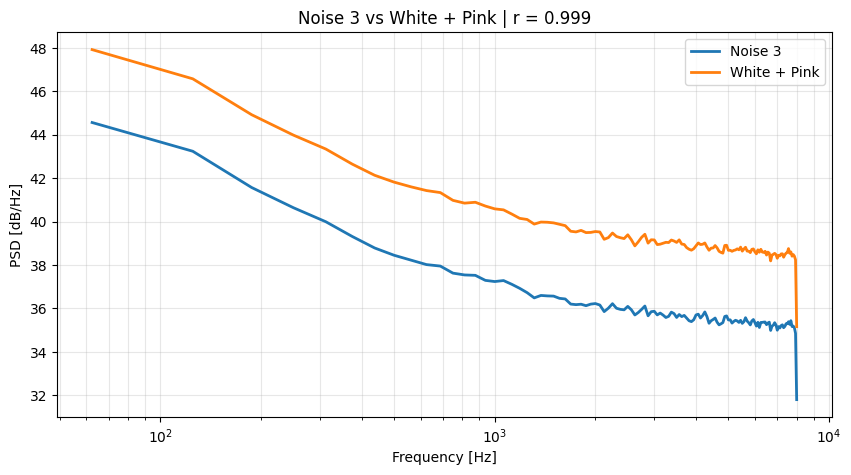

In [5]:
white, pink, noise3_signal = noise1.data, noise2.data, noise3.data
fs = noise1.rate

# PSDs
f, psd_white = welch(white, fs=fs)
f = f[1:]
psd_white = psd_white[1:]
_, psd_pink = welch(pink, fs=fs)
psd_pink = psd_pink[1:]
_, psd_3 = welch(noise3_signal, fs=fs)
psd_3 = psd_3[1:]
_, psd_mix = welch(white + pink, fs=fs)
psd_mix = psd_mix[1:]

psd_3_db = 10 * np.log10(psd_3)
psd_mix_db = 10 * np.log10(psd_mix)


# 1. Noise 3 vs White + Pink
r_mix, _ = pearsonr(psd_3_db, psd_mix_db)

plt.figure(figsize=(10, 5))
plt.semilogx(f, psd_3_db, linewidth=2, label="Noise 3")
plt.semilogx(f, psd_mix_db, linewidth=2, label="White + Pink")
plt.xlabel("Frequency [Hz]")
plt.ylabel("PSD [dB/Hz]")
plt.title(f"Noise 3 vs White + Pink | r = {r_mix:.3f}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Mean difference: 3.307 dB
STD difference:  0.067 dB
Scaling factor: 0.467


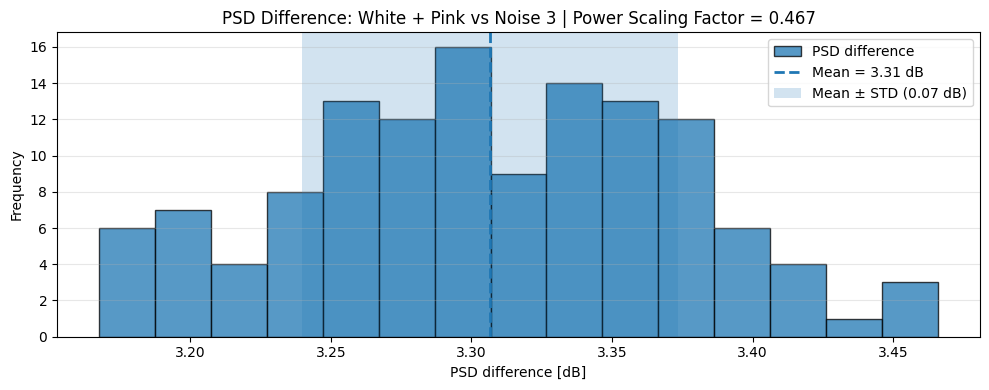

In [6]:
# 2. PSD difference
diff_db = psd_mix_db - psd_3_db
mean_diff, std_diff = np.mean(diff_db), np.std(diff_db)

scaling_factor = 10 ** (-mean_diff / 10)

print(f"Mean difference: {mean_diff:.3f} dB")
print(f"STD difference:  {std_diff:.3f} dB")
print(f"Scaling factor: {scaling_factor:.3f}")

plt.figure(figsize=(10, 4))
plt.hist(diff_db, bins=15, alpha=0.75, edgecolor="black", label="PSD difference")

plt.axvline(mean_diff, linestyle="--", linewidth=2,
            label=f"Mean = {mean_diff:.2f} dB")

plt.axvspan(mean_diff - std_diff, mean_diff + std_diff, alpha=0.2,
            label=f"Mean ± STD ({std_diff:.2f} dB)")

plt.xlabel("PSD difference [dB]")
plt.ylabel("Frequency")
plt.title(f"PSD Difference: White + Pink vs Noise 3 | Power Scaling Factor = {scaling_factor:.3f}")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Insights

> The PSD of **Noise 3** closely follows the spectral shape of the artificial **White + Pink** mixture.
>
> This similarity is confirmed by the **Pearson correlation coefficient (`r ≈ 1.00`)**, indicating that both spectra have almost the same frequency-dependent structure.
>
> The difference between the two PSDs is approximately **3.17 ± 0.10 dB** across frequency. Since the standard deviation is very small, this offset remains nearly constant over the entire frequency range. This suggests that the main difference between the signals is an **overall power scaling**. The similarity in shape is also consistent with **White and Pink noise contributing in roughly similar proportions**.
>
> Since the **White + Pink** PSD is approximately **3.17 dB above Noise 3**, the corresponding power scaling factor is:
>
> $$
> S_{\text{power}} = 10^{-3.17/10} \approx 0.482
> $$
>
> Thus, **Noise 3** can be approximated as:
>
> $$
> PSD_{\text{Noise 3}}(f)
> \approx
> 0.482
> \left(
> PSD_{\text{White}}(f) + PSD_{\text{Pink}}(f)
> \right)
> $$
>
> Overall, these results support the hypothesis that **Noise 3 is approximately a scaled mixture of White and Pink noise**, with both components appearing to contribute in similar proportions.

---

## 4. Simulation of Noisy Signals at Different SNR Levels Using Gaussian White Noise

Before simulating noisy versions of the original signal, it is important to understand three main concepts: **signal power**, **Signal-to-Noise Ratio (SNR)**, and **Gaussian white noise**. These concepts determine how much noise must be added to obtain a specific SNR.

### Signal Power

For a discrete signal $x[n]$, its average power in the time domain is defined as

$$
P_x = \frac{1}{N}\sum_{n=0}^{N-1} x[n]^2
$$

where $N$ is the number of samples.

This value represents the average power of the signal and will later be used to compare the power of the clean signal with the power of the added noise.

### Signal-to-Noise Ratio

The **Signal-to-Noise Ratio (SNR)** measures the relative power of the desired signal compared with the noise affecting it. It is usually expressed in decibels:

$$
\mathrm{SNR}_{dB} = 10\log_{10}\left(\frac{P_{\text{signal}}}{P_{\text{noise}}}\right)
$$

A higher SNR indicates that the signal is dominant over the noise, whereas a lower SNR means that the noise has a stronger contribution.


### Gaussian White Noise

In this exercise, the added noise is modeled as **Gaussian white noise**.

Each noise sample is independently drawn from a normal distribution:

$$
n[n] \sim \mathcal{N}(0,\sigma)
$$

where the mean is $0$ and the variance is $1$.


### Scaling the Noise to Obtain a Desired SNR

The noisy signal can be expressed as

$$
y[n] = x[n] + \alpha n[n]
$$

where $x[n]$ is the clean signal, $n[n]$ is the Gaussian white noise, and $\alpha$ is a scaling factor that controls the noise amplitude.

The power of the signal is equivalent to:
$$
P_{y} = \frac{1}{N}\sum_{n=0}^{N-1} y[n]^2
$$
as result:
$$
P_{y} = P_x + P_n
$$
The power of the scaled noise is

$$
P_{\alpha n} = \alpha^2 P_n
$$

because multiplying a signal by $\alpha$ multiplies its power by $\alpha^2$.

Substituting this into the definition of SNR gives
$$
{SNR}_{dB}
=
10\log_{10}
\left(
\frac{P_x}{\alpha^2 P_n}
\right)
$$

Solving this expression for $\alpha$ gives

$$
\alpha =
\sqrt{
\frac{P_x}
{P_n\,10^{\mathrm{SNR}_{dB}/10}}
}
$$

Therefore, the procedure consists of generating Gaussian white noise, calculating the power of both the original signal and the noise, scaling the noise using $\alpha$, and finally adding it to the clean signal.

Using this approach, noisy versions of the original signal can be generated at **0, 5, 10, 15, and 20 dB**, allowing the effect of different noise levels on the signal to be analyzed.

In [7]:
# Essential functions

def generate_white_noise(N,factor=100):
    return factor *np.random.normal(0.0, 1, N)


def signal_power(x):
    """Mean signal power in the time domain."""
    x = np.asarray(x, dtype=np.float64)
    return np.mean(x**2)



def calculate_snr(clean, test):
    """SNR of test relative to a known clean reference, in dB."""
    clean = np.asarray(clean, dtype=np.float64)
    test = np.asarray(test, dtype=np.float64)
    error = test - clean
    return 10 * np.log10( signal_power(clean) / signal_power(error))


def add_noise_snr(x, noise, snr_db):
    """Scale noise so that y = x + n has the requested SNR."""
    x = np.asarray(x, dtype=np.float64)
    noise = np.asarray(noise, dtype=np.float64)

    Px = signal_power(x)
    Pn = signal_power(noise)

    alpha = np.sqrt(
        Px / (Pn * 10**(snr_db / 10))
    )

    noise_scaled = alpha * noise
    y = x + noise_scaled

    return y, noise_scaled


white_noise = generate_white_noise(len(audio_signal.data))

## 4.1 Gaussian White Noise Simulation and Factor Analysis

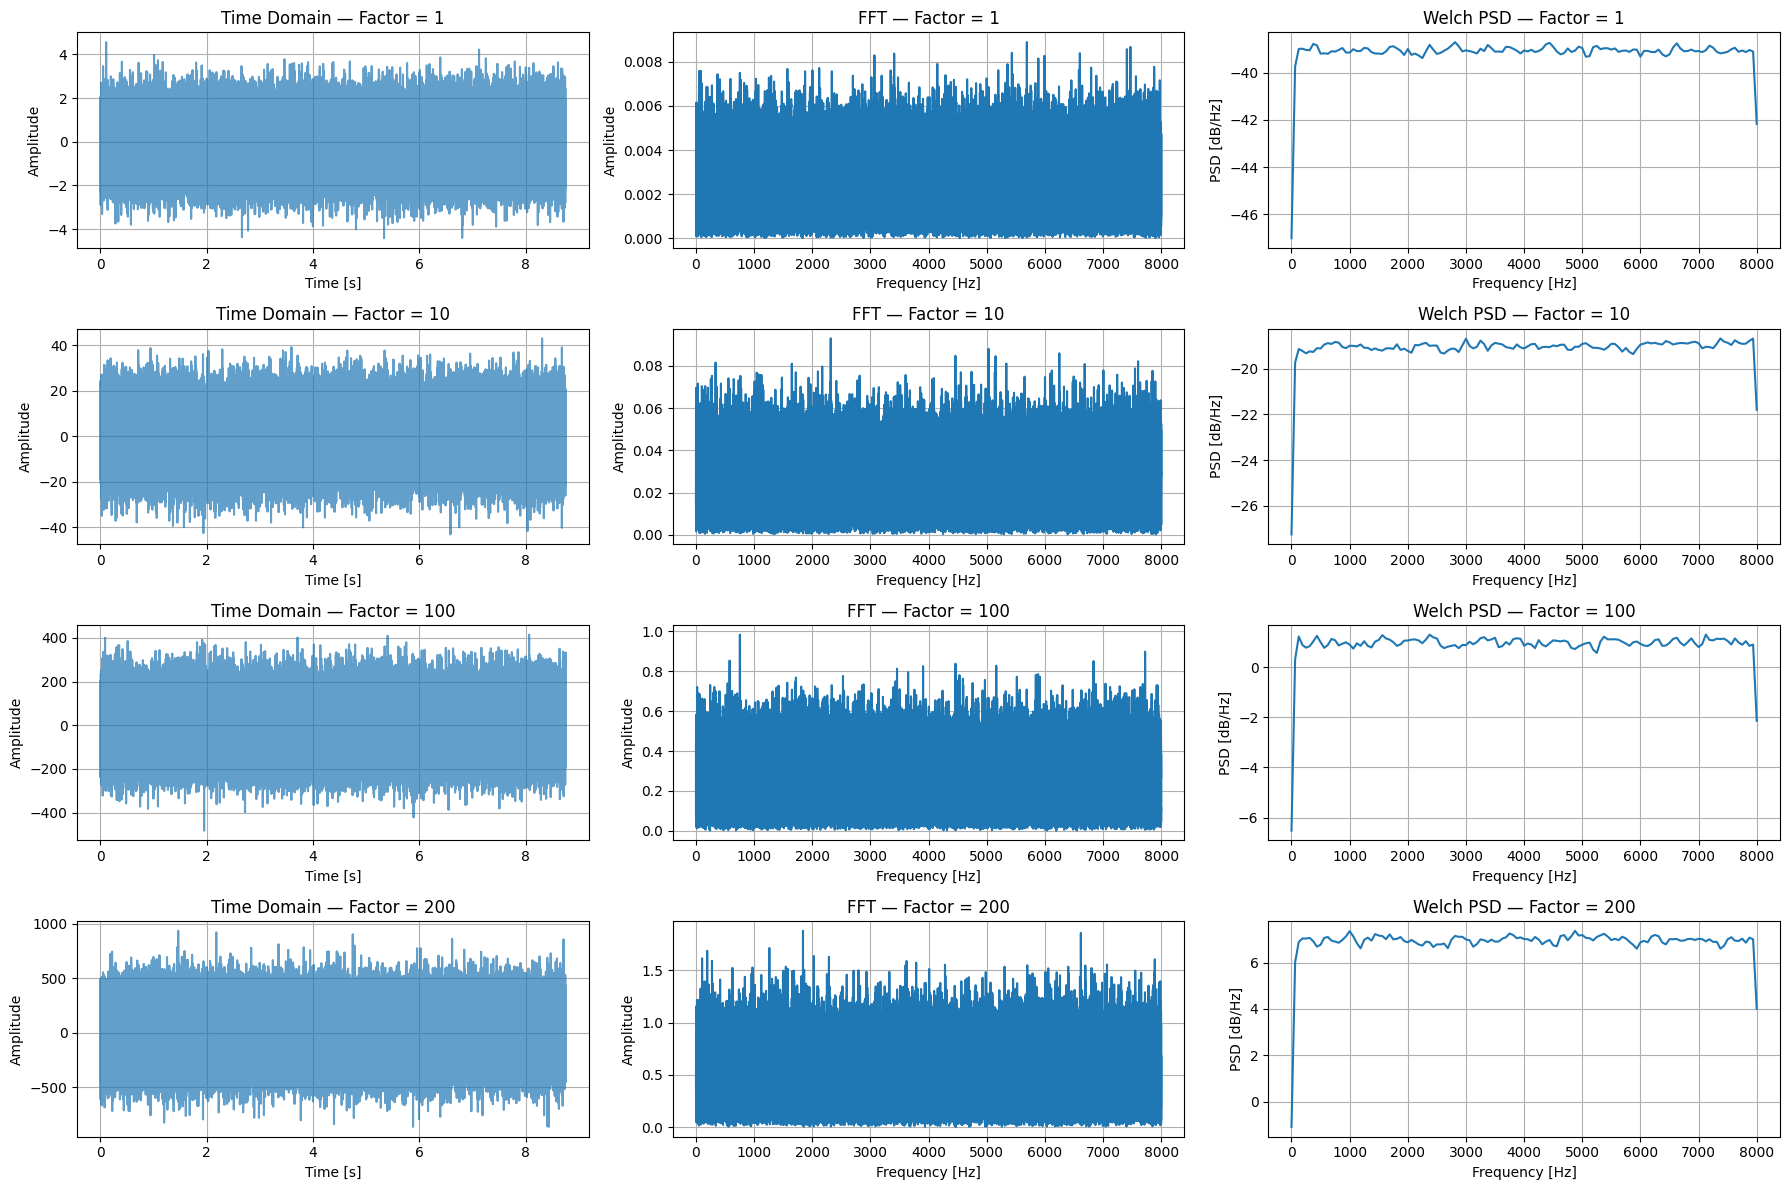

In [8]:
factors = [1, 10, 100,200]

fig, axes = plt.subplots(4, 3, figsize=(18, 12))

for i, factor in enumerate(factors):

    white_noise = generate_white_noise(len(audio_signal.data), factor=factor)

    # 1. TIME DOMAIN
    axes[i, 0].plot(audio_signal.time, white_noise, alpha=0.7)
    axes[i, 0].set_title(f"Time Domain — Factor = {factor}")
    axes[i, 0].set_xlabel("Time [s]")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid()

    # 2. FFT
    N = len(white_noise)
    fft = np.fft.rfft(white_noise)
    freq = np.fft.rfftfreq(N, d=1/audio_signal.rate)
    amplitude = np.abs(fft) / N

    axes[i, 1].plot(freq, amplitude)
    axes[i, 1].set_title(f"FFT — Factor = {factor}")
    axes[i, 1].set_xlabel("Frequency [Hz]")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid()

    # 3. WELCH PSD
    f, psd = welch(white_noise, fs=audio_signal.rate)

    axes[i, 2].plot(f, 10 * np.log10(psd))
    axes[i, 2].set_title(f"Welch PSD — Factor = {factor}")
    axes[i, 2].set_xlabel("Frequency [Hz]")
    axes[i, 2].set_ylabel("PSD [dB/Hz]")
    axes[i, 2].grid()

plt.tight_layout()
plt.show()

>The **factor** used to generate the white noise controls its overall amplitude. Increasing this factor increases the amplitude of the noise in the time domain and, consequently, the magnitude of its frequency components in the frequency domain. This makes the effect of the noise on the original signal easier to observe and analyze. In our case, we will use a **factor of 100** to obtain a sufficiently strong noise signal and clearly visualize its influence on the signal.

## 4.2 Effect of Gaussian White Noise at Different SNR Levels on the Signal

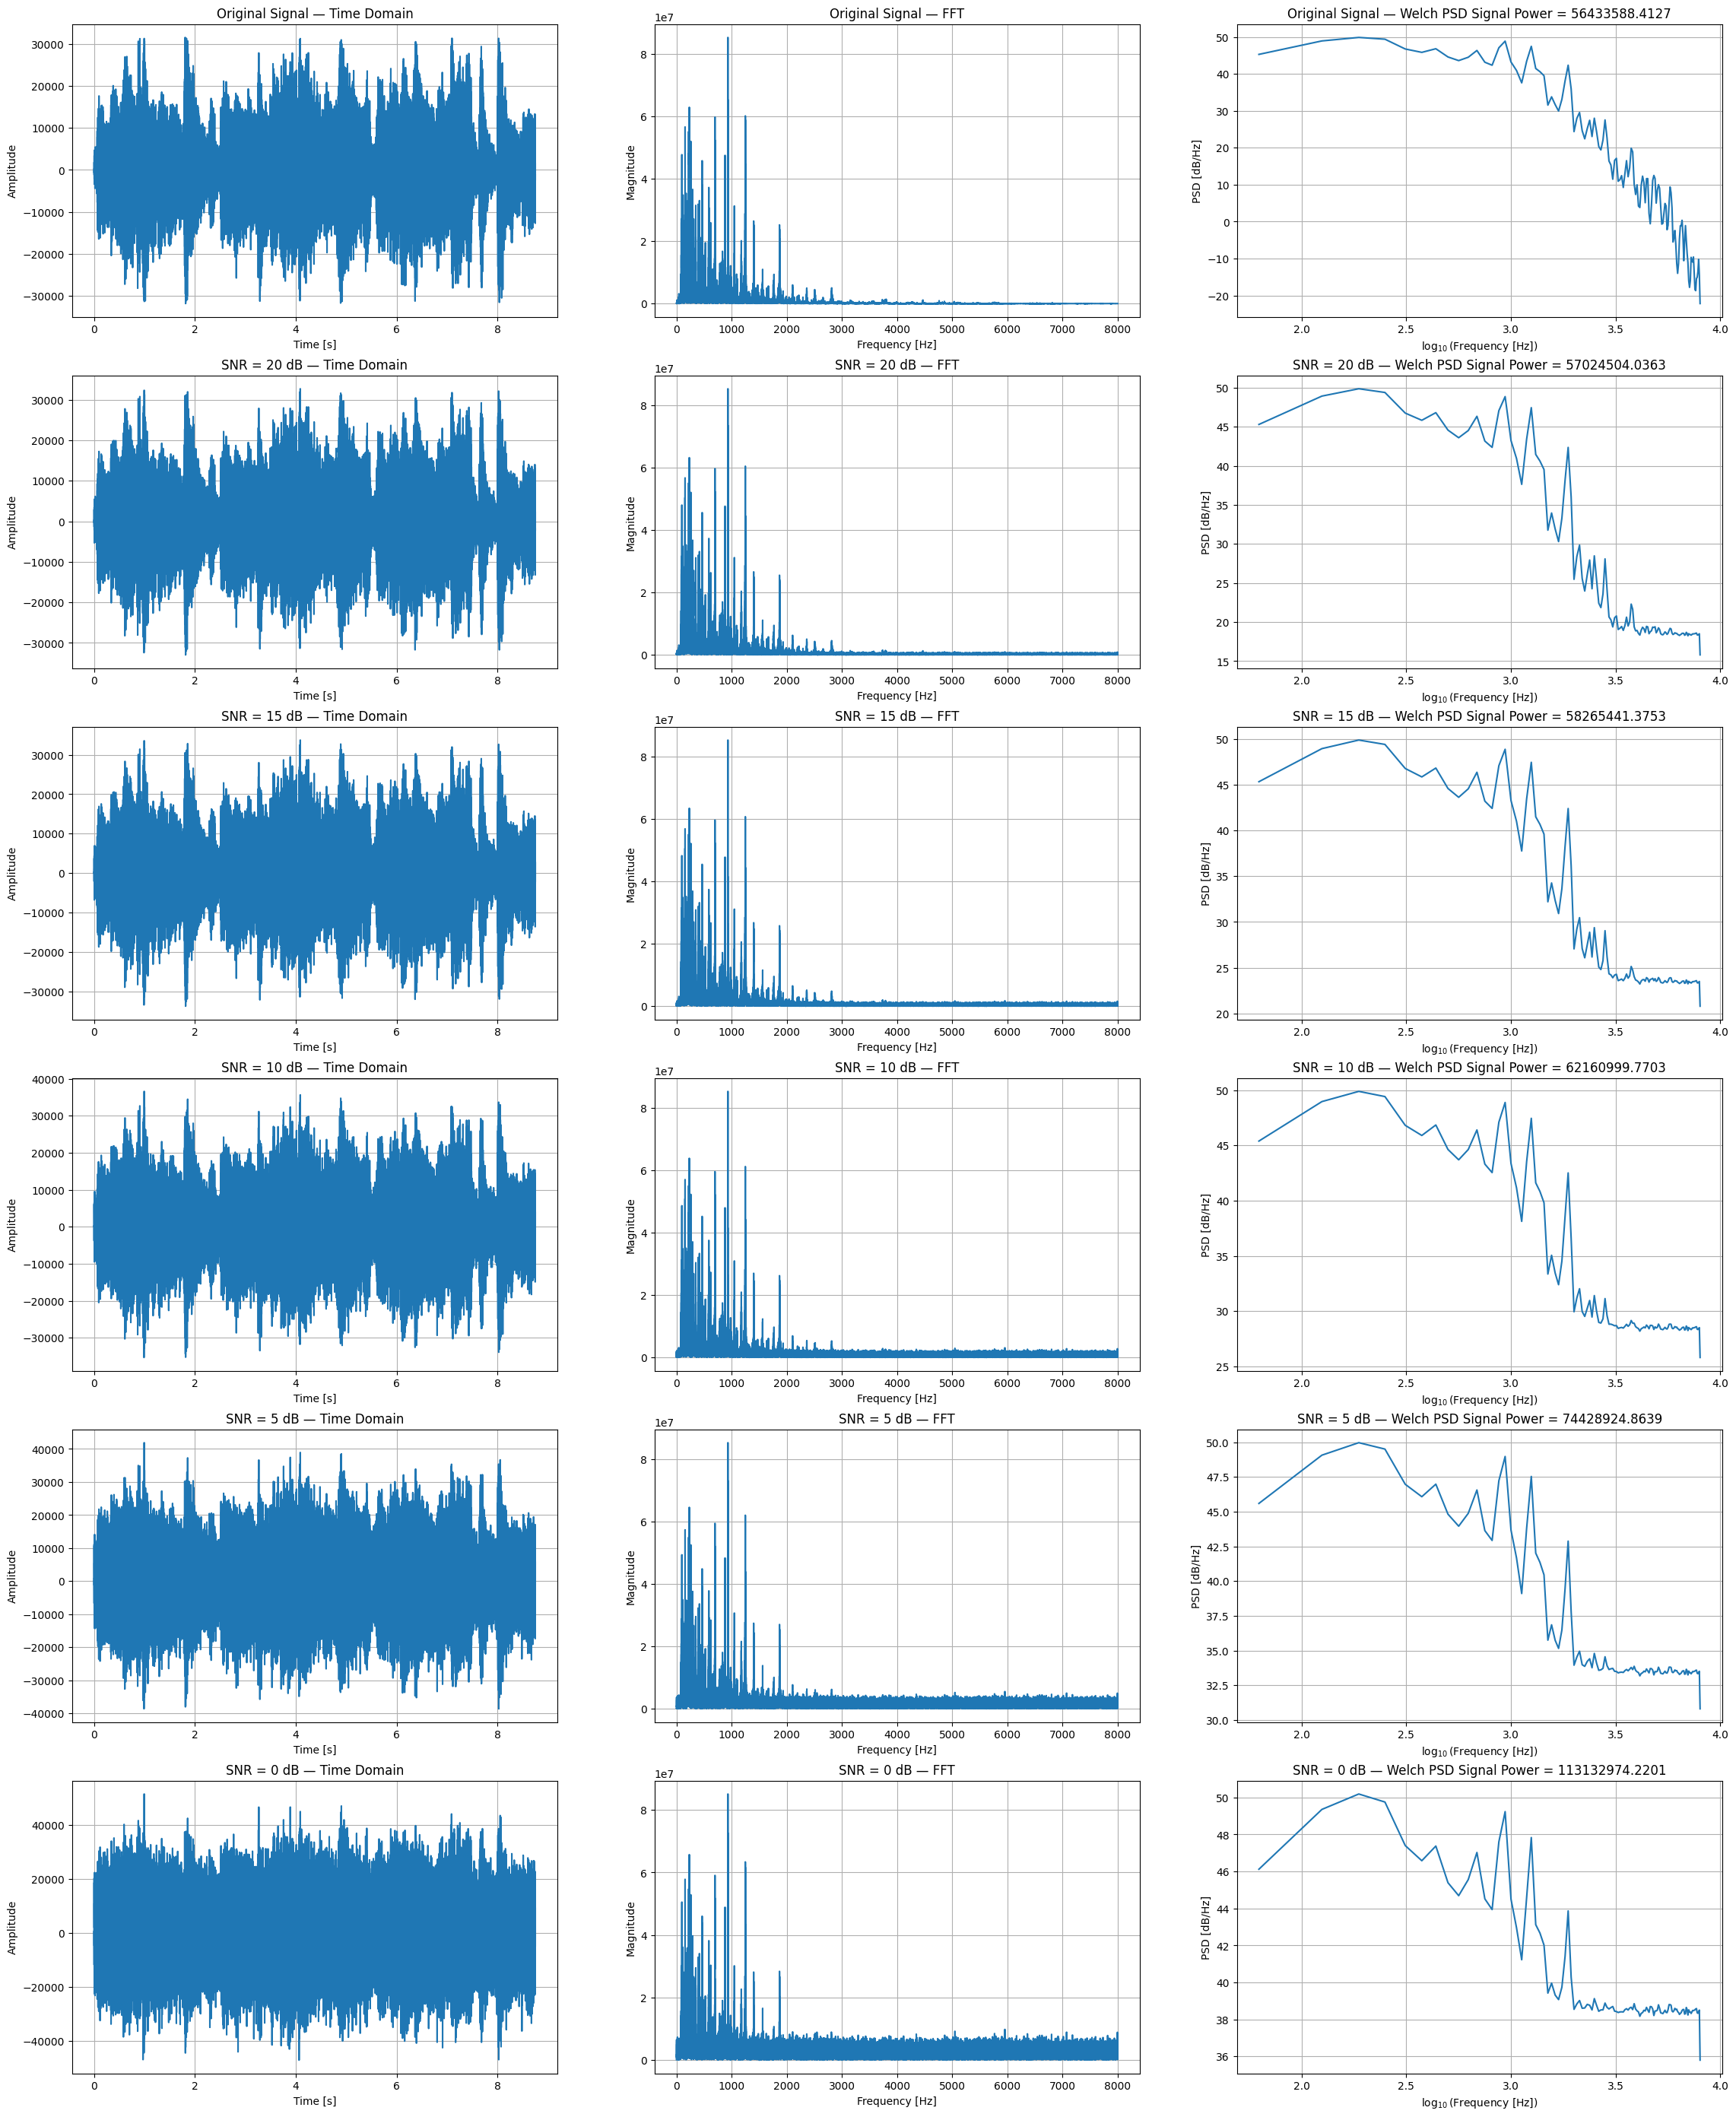

In [9]:
noise_levels = [20,15,10,5,0]
white_noise = generate_white_noise(len(audio_signal.data))

fs = audio_signal.rate
x = audio_signal.data
t = audio_signal.time

signals = [x]
labels = ["Original Signal"]

for snr_db in noise_levels:
    noisy_signal, scaled_noise = add_noise_snr(x, white_noise, snr_db)

    signals.append(noisy_signal)
    labels.append(f"SNR = {snr_db} dB")
    write(f"data/signal_with_noise/noisy_signal_{snr_db}dB.wav", fs, noisy_signal.astype(np.float32))

fig, axes = plt.subplots( len(signals), 3, figsize=(28, 35))

for i, (signal, label) in enumerate(zip(signals, labels)):

    # 1. TIME DOMAIN
    axes[i, 0].plot(t[:len(signal)], signal)
    axes[i, 0].set_title(f"{label} — Time Domain")
    axes[i, 0].set_xlabel("Time [s]")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True)

    # 2. FFT
    N = len(signal)
    fft_signal = rfft(signal)
    fft_freq = rfftfreq(N, d=1/fs)
    fft_magnitude = np.abs(fft_signal)

    axes[i, 1].plot(fft_freq, fft_magnitude)
    axes[i, 1].set_title(f"{label} — FFT")
    axes[i, 1].set_xlabel("Frequency [Hz]")
    axes[i, 1].set_ylabel("Magnitude")
    axes[i, 1].grid(True)

    # 3. WELCH PSD
    f, psd = welch(signal, fs=fs)
    f_log = np.log10(f[1:])
    psd_log = 10 * np.log10(psd[1:])
    p_signal = signal_power(signal)

    axes[i, 2].plot(f_log, psd_log)
    axes[i, 2].set_title(f"{label} — Welch PSD Signal Power = {p_signal:.4f}")
    axes[i, 2].set_xlabel(r"$\log_{10}(\mathrm{Frequency\ [Hz]})$")
    axes[i, 2].set_ylabel("PSD [dB/Hz]")
    axes[i, 2].grid(True)

plt.show()


## Insights

> As the **SNR decreases**, the influence of the added Gaussian white noise becomes progressively stronger and can be observed in all three representations.
>
> **1. Signal power increases as the SNR decreases.**  
> The original signal has a power of approximately **0.0526**, while the power progressively increases as more noise is added, reaching approximately **0.1049 at 0 dB**. This is expected because the power of the noisy signal is approximately the sum of the signal and noise powers:
>
> $$
> P_{\text{noisy}} \approx P_{\text{signal}} + P_{\text{noise}}
> $$
>
> At **0 dB SNR**, signal and noise have approximately the same power, so the total power is expected to be close to twice the original signal power, which agrees very well with the observed result.
>
> **2. The FFT shows an increasing broadband noise floor.**  
> As the SNR decreases, the amplitude of the frequencis increases. This effect is particularly visible at **higher frequencies**, where the original signal contains relatively little energy. Since white noise contains a constant energy across the entire frequency range, decreasing the SNR progressively raises the broadband spectral floor.
>
> **3. The Welch PSD clearly reveals the contribution of white noise.**  
> The original signal presents a strong decrease in PSD at high frequencies. After adding Gaussian white noise, the high-frequency region progressively becomes **flatter**, approaching a slope of approximately **0**, which is the characteristic spectral behavior of white noise. As the SNR decreases, this flat region becomes increasingly dominant and extends over a larger part of the spectrum.
>


## 4.3 Wiener filtering Reconstruction

For an observed signal

$$
y(t)=x(t)+n(t),
$$

the PSD of the clean signal can be estimated, assuming signal and noise are uncorrelated, as

$$
\hat S_x(f)=S_y(f)-S_n(f).
$$

The Wiener frequency response is then

$$
H(f)=\frac{\hat S_x(f)}
{\hat S_x(f)+S_n(f)}.
$$

The processing chain is

$$
\boxed{
y(t),n(t)
\rightarrow
\text{Welch}
\rightarrow
S_y(f),S_n(f)
\rightarrow
\hat S_x(f)
\rightarrow
H(f)
\rightarrow
Y(f)H(f)
\rightarrow
\text{IFFT}
\rightarrow
\hat x(t)
}
$$

> **Important we apply Zero-padding before frequency-domain filtering**
>
> Since the analyzed audio signal is **not periodic**, the DFT implicitly assumes a periodic repetition of the signal. Therefore, directly multiplying $Y(f)$ by the Wiener filter $H(f)$ and applying the IFFT can introduce **circular-convolution (wrap-around) artifacts**, where the end of the signal interacts with its beginning.


In [10]:
def wiener_filter(signal, noise, rate):
    """Frequency-domain Wiener filter using Welch PSD estimates."""

    signal = np.asarray(signal, dtype=np.float64)
    noise = np.asarray(noise, dtype=np.float64)


    # PSD estimates
    f, psd_signal = welch(signal, fs=rate)
    _, psd_noise = welch(noise, fs=rate)

    # Estimate clean-signal PSD.
    # Clipping prevents non-physical negative PSD values.
    psd_clean = psd_signal - psd_noise

    # Wiener gain
    H_wiener = psd_clean / (psd_clean + psd_noise)

    # Zero-padding reduces circular wrap-around effects
    N = len(signal)
    N_pad = 2 * N

    signal_fft = rfft(signal, n=N_pad)
    f_fft = rfftfreq(N_pad, d=1 / rate)

    # Interpolate Wiener gain onto FFT frequency bins
    H = np.interp(f_fft, f, H_wiener)

    filtered_fft = signal_fft * H
    filtered_signal = irfft(filtered_fft, n=N_pad)

    return filtered_signal[:N]

In [11]:
original_signal = audio_signal.data
rate = audio_signal.rate

results = []
filtered_signals = {}

for snr_db in noise_levels:

    noisy_signal, scaled_noise = add_noise_snr(
        original_signal,
        white_noise,
        snr_db
    )

    filtered_signal = wiener_filter(
        noisy_signal,
        scaled_noise,
        rate
    )

    filtered_signals[snr_db] = filtered_signal

    # SNR-based evaluation
    snr_before = calculate_snr(original_signal, noisy_signal)
    snr_after = calculate_snr(original_signal, filtered_signal)

    # True signal power (time domain)
    power_noisy = signal_power(noisy_signal)
    power_filtered = signal_power(filtered_signal)



    results.append({
        "SNR target [dB]": snr_db,
        "SNR before [dB]": snr_before,
        "SNR after [dB]": snr_after,
        "SNR improvement [dB]": snr_after - snr_before,
        "Power noisy": power_noisy,
        "Power filtered": power_filtered,

    })

df = pd.DataFrame(results)

print(f"Original signal power: {signal_power(original_signal):.6f}")

df.round(6)

Original signal power: 56433588.412654


,SNR target [dB],SNR before [dB],SNR after [dB],SNR improvement [dB],Power noisy,Power filtered
0,20,20.0,24.148075,4.148075,5.702450e+07,5.627973e+07
1,15,15.0,19.962908,4.962908,5.826544e+07,5.600507e+07
2,10,10.0,15.799459,5.799459,6.216100e+07,5.526891e+07
3,5,5.0,11.734158,6.734158,7.442892e+07,5.332252e+07
4,0,0.0,7.935998,7.935998,1.131330e+08,4.840110e+07


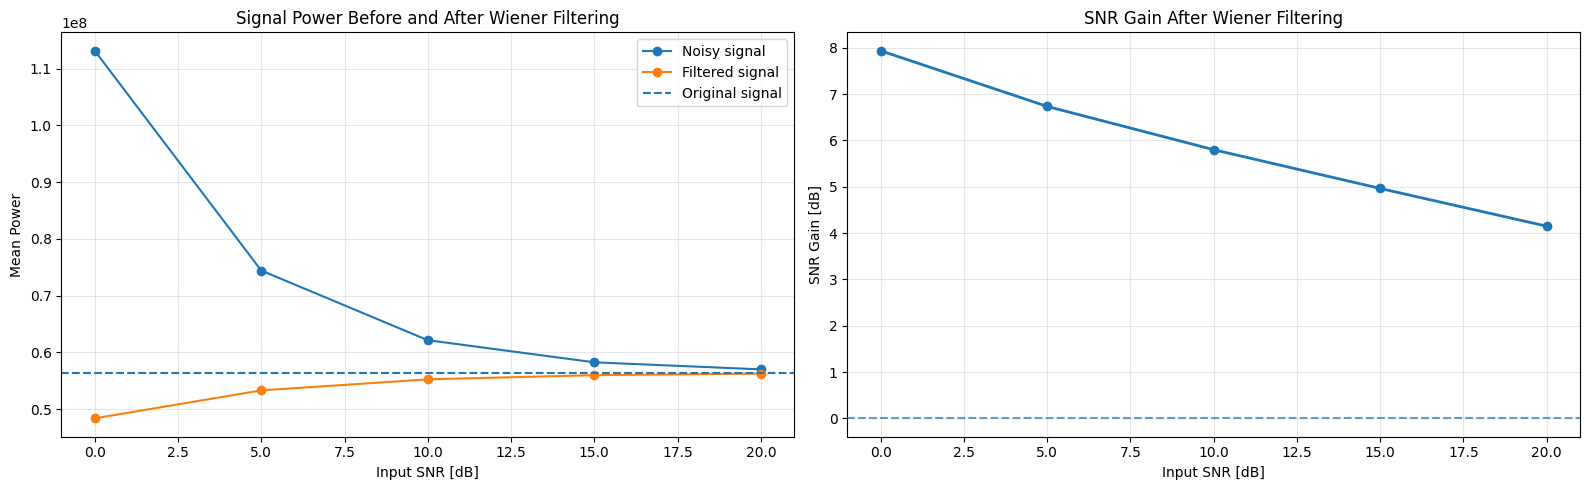

In [12]:
power_original = signal_power(original_signal)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Signal power
axes[0].plot(df["SNR target [dB]"], df["Power noisy"], "o-", label="Noisy signal")
axes[0].plot(df["SNR target [dB]"], df["Power filtered"], "o-", label="Filtered signal")
axes[0].axhline(power_original, linestyle="--", label="Original signal")

axes[0].set_xlabel("Input SNR [dB]")
axes[0].set_ylabel("Mean Power")
axes[0].set_title("Signal Power Before and After Wiener Filtering")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# 2. SNR gain
axes[1].plot(
    df["SNR target [dB]"],
    df["SNR improvement [dB]"],
    "o-",
    linewidth=2
)

axes[1].axhline(0, linestyle="--", alpha=0.7)
axes[1].set_xlabel("Input SNR [dB]")
axes[1].set_ylabel("SNR Gain [dB]")
axes[1].set_title("SNR Gain After Wiener Filtering")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Insights
> The Wiener filter improves the SNR for all the tested noise levels, although it does not perfectly reconstruct the original clean signal. This is expected, since the filter estimates the clean signal from the spectral statistics of the noisy signal and the known white noise rather than performing an exact inversion.
>
>The power analysis shows that, after filtering, the reconstructed signal moves towards the power of the original signal. However, especially at very low input SNR, some useful signal components are also attenuated. For example, at 0 dB, the filtered signal has a noticeably lower power than the original signal, indicating that part of the signal is lost together with the noise.
>
>The SNR gain presents a clear trend: the noisier the input signal, the larger the improvement produced by the Wiener filter. The gain decreases from approximately 8 dB at an input SNR of 0 dB to approximately 4 dB at 20 dB. This occurs because, when the input signal already has a high SNR, there is less noise available for the filter to remove and therefore less room for improvement.
>
>Therefore, the Wiener filter is particularly effective in terms of SNR improvement for strongly contaminated signals, while still providing a positive improvement for cleaner signals. However, the relationship between input SNR and SNR gain is non-linear and monotonically decreasing.

# 5. String Analysis — Additional Content

Given the previous understanding of the Wiener filter, I decided to apply it to one of the guitar-string recordings provided for the first two practical sessions.

An interesting characteristic of this recording is that its first seconds contain mainly background noise, before the guitar string is played. This gives us a useful noise-only segment that can be exploited to estimate the noise characteristics directly from the recording.

Based on this observation, the analysis is divided into three steps:

1. **Noise characterization:** use the initial noise-only segment and estimate its Power Spectral Density (PSD) with Welch's method to identify the spectral characteristics of the background noise.

2. **Noise simulation:** based on the observed PSD, simulate a noise signal with similar spectral properties over the entire duration of the guitar recording.

3. **Signal reconstruction:** use the estimated/simulated noise information to construct a Wiener filter and recover a cleaner version of the guitar-string signal by attenuating frequency components dominated by noise.

Therefore, this additional experiment provides a practical application of the Wiener filtering framework to a real audio signal, where the noise statistics can be estimated directly from a noise-only portion of the recording.

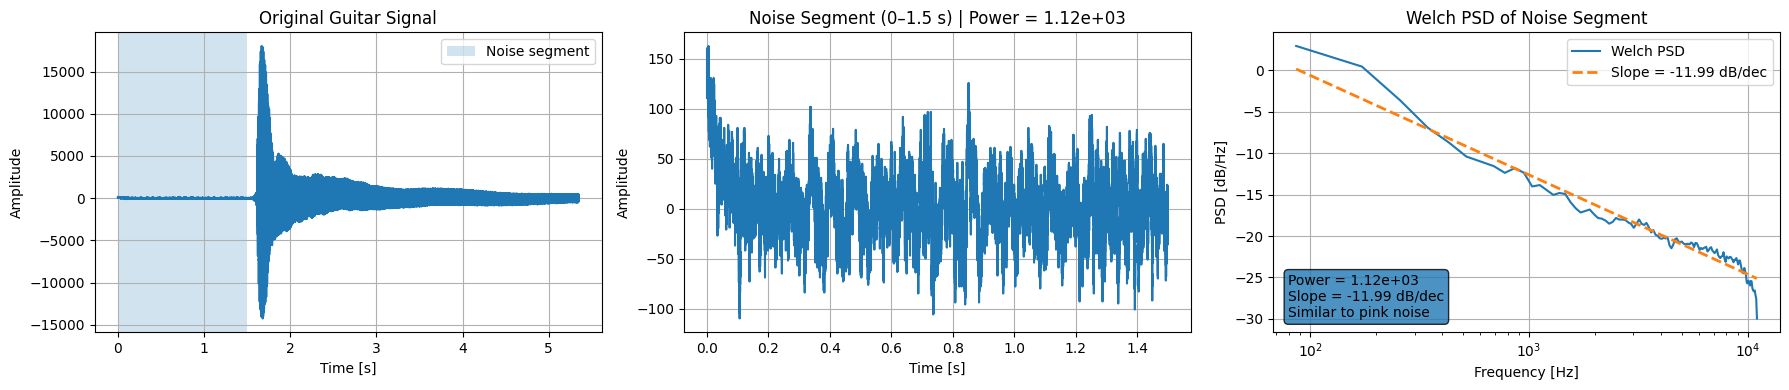

In [13]:
string = signal_data('data/string_guitar.wav')

# Noise segment: first 1.5 seconds
noise_segment = string.data[:int(1.5 * string.rate)]
noise_time = np.arange(len(noise_segment)) / string.rate

# Noise power
noise_power = np.mean(noise_segment**2)

# Welch PSD
f_noise, psd_noise = welch(noise_segment, fs=string.rate)

# Remove DC
f_fit = f_noise[1:]
psd_noise_db = 10 * np.log10(psd_noise[1:])

# Linear fit in log-frequency domain
slope, intercept = np.polyfit(np.log10(f_fit), psd_noise_db, 1)
psd_fit_db = slope * np.log10(f_fit) + intercept

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Full signal
axes[0].plot(string.time, string.data)
axes[0].axvspan(0, 1.5, alpha=0.2, label="Noise segment")
axes[0].set_title("Original Guitar Signal")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

# 2. Noise segment
axes[1].plot(noise_time, noise_segment)
axes[1].set_title(f"Noise Segment (0–1.5 s) | Power = {noise_power:.2e}")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

# 3. Welch PSD + slope
axes[2].semilogx(f_fit, psd_noise_db, label="Welch PSD")
axes[2].semilogx(f_fit, psd_fit_db, "--", linewidth=2, label=f"Slope = {slope:.2f} dB/dec")
axes[2].set_title("Welch PSD of Noise Segment")
axes[2].set_xlabel("Frequency [Hz]")
axes[2].set_ylabel("PSD [dB/Hz]")
axes[2].legend()
axes[2].grid(True)

# Information box
axes[2].text(
    0.03, 0.05,
    f"Power = {noise_power:.2e}\n"
    f"Slope = {slope:.2f} dB/dec\n"
    f"Similar to pink noise",
    transform=axes[2].transAxes,
    bbox=dict(boxstyle="round", alpha=0.8)
)

plt.tight_layout()
plt.show()

### Insights

> As observed in the time-domain signal, the first **1.5 s** of the recording contain only background noise. This segment can therefore be used to characterize the noise independently of the guitar signal.
>
> The **Welch PSD** of this segment shows an approximately linear decay in the logarithmic frequency domain, with a fitted slope of about **−12 dB/decade**. This value is reasonably close to the theoretical **−10 dB/decade** slope associated with **pink noise**, whose power spectral density follows approximately
>
> $$
> S_n(f) \propto \frac{1}{f}.
> $$
>
> Based on this observation, the background noise can be approximated as **pink noise**. This provides a basis for simulating a noise signal with similar spectral characteristics over the full duration of the recording and subsequently using it for Wiener filtering.
>
> This approach relies on the assumption that the noise is **approximately stationary throughout the recording**, meaning that the same type of noise and similar spectral characteristics observed during the initial 1.5 s remain present while the guitar string is sounding.

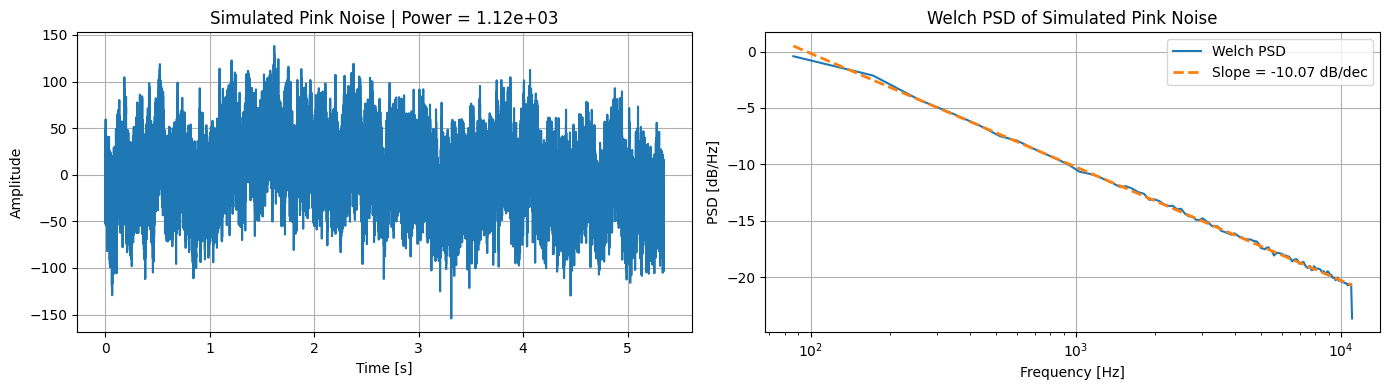

In [14]:
def generate_pink_noise(N, target_power):
    white = np.random.normal(0, 1, N)

    spectrum = np.fft.rfft(white)
    f = np.fft.rfftfreq(N)

    f[0] = np.inf
    spectrum *= 1 / np.sqrt(f)

    pink = np.fft.irfft(spectrum, n=N)

    # Scale to desired power
    current_power = np.mean(pink**2)
    pink *= np.sqrt(target_power / current_power)

    return pink

pink_noise = generate_pink_noise(len(string.data), noise_power)

# Welch PSD
f_pink, psd_pink = welch(pink_noise, fs=string.rate)
f_fit = f_pink[1:]
psd_pink_db = 10 * np.log10(psd_pink[1:])

# Spectral slope
slope, intercept = np.polyfit(np.log10(f_fit), psd_pink_db, 1)
psd_fit_db = slope * np.log10(f_fit) + intercept

# Power
pink_power = np.mean(pink_noise**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Time domain
axes[0].plot(string.time, pink_noise)
axes[0].set_title(f"Simulated Pink Noise | Power = {pink_power:.2e}")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

# Welch PSD
axes[1].semilogx(f_fit, psd_pink_db, label="Welch PSD")
axes[1].semilogx(f_fit, psd_fit_db, "--", linewidth=2,
                 label=f"Slope = {slope:.2f} dB/dec")
axes[1].set_title("Welch PSD of Simulated Pink Noise")
axes[1].set_xlabel("Frequency [Hz]")
axes[1].set_ylabel("PSD [dB/Hz]")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Insights

> It is essential to simulate the pink noise using the **same noise power estimated from the noise-only region of the original guitar recording**.
>
> This is particularly important for Wiener filtering because the filter depends on the relative power of the signal and noise. If the simulated noise power is too high or too low, the estimated noise PSD will be incorrect and the filter will either **over-suppress the signal** or **remove too little noise**.
>
> In this case, the simulated signal has a power of approximately
>
> $$
> P_n = 1.04 \times 10^{-6}
> $$
>
> matching the power estimated from the initial noise-only segment.
>
> The Welch PSD also presents a slope of approximately
>
> $$
> -10.07\ \text{dB/decade}
> $$
>
> which is extremely close to the theoretical **$-10$ dB/decade slope of pink noise**.
>
> Therefore, the simulation reproduces both the **spectral shape** and the **power level** of the noise observed in the recording, making it a suitable noise model for the subsequent Wiener filtering step.

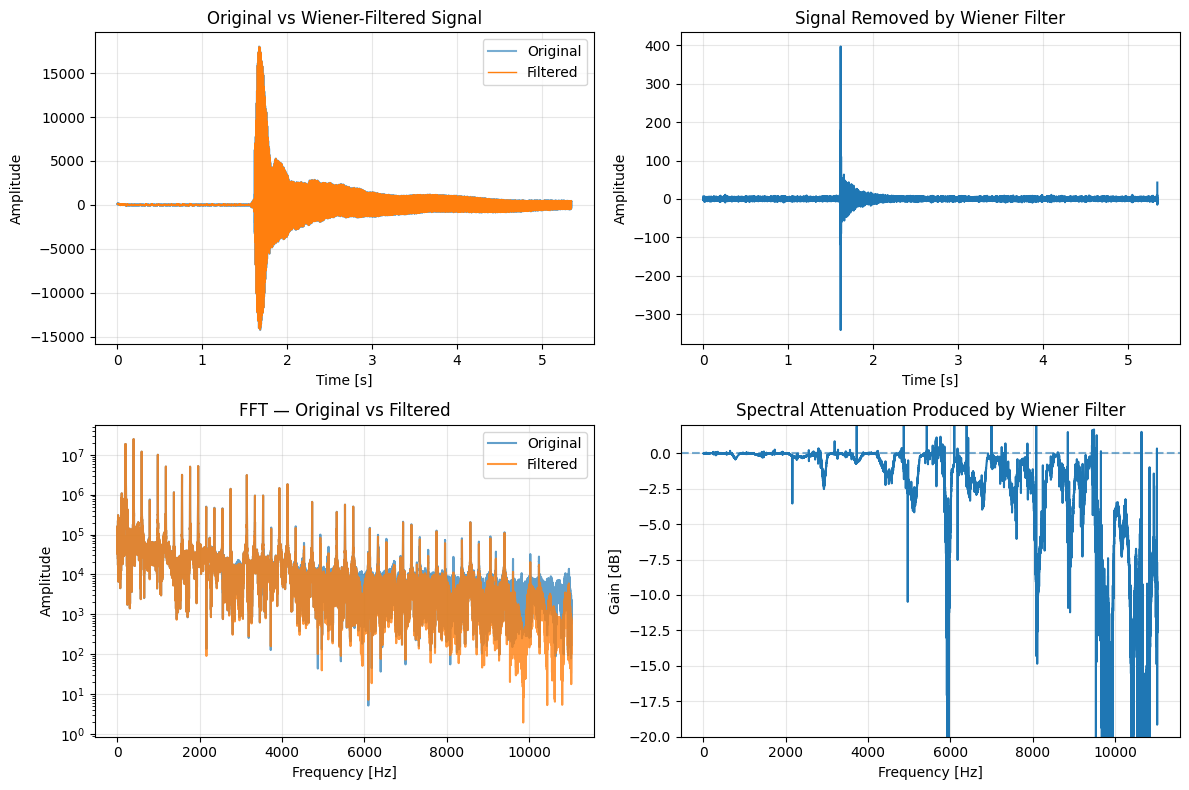

In [15]:
filtered_signal_string = wiener_filter(string.data, pink_noise, string.rate)

# FFT
N = len(string.data)
f_fft = rfftfreq(N, d=1/string.rate)

fft_original = np.abs(rfft(string.data))
fft_filtered = np.abs(rfft(filtered_signal_string))

# Residual removed by the filter
residual = string.data - filtered_signal_string

# Spectral attenuation
eps = 1e-12
attenuation_db = 20 * np.log10((fft_filtered + eps) / (fft_original + eps))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Time domain
axes[0, 0].plot(string.time, string.data, label="Original", alpha=0.6)
axes[0, 0].plot(string.time, filtered_signal_string, label="Filtered", linewidth=1)
axes[0, 0].set_title("Original vs Wiener-Filtered Signal")
axes[0, 0].set_xlabel("Time [s]")
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Removed component
axes[0, 1].plot(string.time, residual)
axes[0, 1].set_title("Signal Removed by Wiener Filter")
axes[0, 1].set_xlabel("Time [s]")
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].grid(alpha=0.3)

# 3. FFT 
axes[1, 0].plot(f_fft, fft_original, label="Original", alpha=0.7)
axes[1, 0].plot(f_fft, fft_filtered, label="Filtered", alpha=0.8)
axes[1, 0].set_yscale("log")
axes[1, 0].set_title("FFT — Original vs Filtered")
axes[1, 0].set_xlabel("Frequency [Hz]")
axes[1, 0].set_ylabel("Amplitude")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Spectral attenuation
axes[1, 1].plot(f_fft, attenuation_db)
axes[1, 1].axhline(0, linestyle="--", alpha=0.6)
axes[1, 1].set_title("Spectral Attenuation Produced by Wiener Filter")
axes[1, 1].set_xlabel("Frequency [Hz]")
axes[1, 1].set_ylabel("Gain [dB]")
axes[1, 1].set_ylim(-20, 2)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Estimated powers
P_observed = signal_power(string.data)
P_noise = signal_power(pink_noise)

P_clean_est = P_observed - P_noise
P_estimation_wiener = signal_power(filtered_signal_string)

# Initial SNR
SNR_initial = 10 * np.log10(P_clean_est / P_noise)

# Residual after Wiener filtering
residual = string.data - filtered_signal_string
P_residual = signal_power(residual)

# Estimated final SNR
SNR_wiener = 10 * np.log10(P_estimation_wiener / P_residual)

# Improvement
SNR_improvement = SNR_wiener - SNR_initial

print(f"Observed signal power:         {P_observed:.6f}")
print(f"Noise power:                   {P_noise:.6f}")
print(f"Estimated clean signal power:  {P_clean_est:.6f}")
print(f"Wiener filtered signal power:  {P_estimation_wiener:.6f}")
print(f"Residual power:                {P_residual:.6f}")

print(f"\nInitial estimated SNR: {SNR_initial:.2f} dB")
print(f"Wiener estimated SNR:  {SNR_wiener:.2f} dB")
print(f"SNR improvement:       {SNR_improvement:.2f} dB")

Observed signal power:         2068398.118368
Noise power:                   1120.932971
Estimated clean signal power:  2067277.185397
Wiener filtered signal power:  2067655.249990
Residual power:                24.260017

Initial estimated SNR: 32.66 dB
Wiener estimated SNR:  49.31 dB
SNR improvement:       16.65 dB


### Insights

> The filtered signal remains very similar to the original one in the time domain, indicating that the **Wiener filter preserves most of the guitar signal**.
>
> The residual shows that some information is removed, particularly around the **attack of the note**.
>
> In the frequency domain, the **main harmonics are preserved**, while the filter mainly attenuates the **higher-frequency components**, which are more strongly affected by the estimated pink noise.
>
> The estimated initial SNR is **32.66 dB**, indicating that the original recording already contains relatively little noise. After Wiener filtering, the estimated SNR increases to **49.31 dB**, corresponding to an apparent improvement of approximately **16.65 dB**.
>
> Despite this spectral attenuation, **no clear perceptual difference can be noticed when listening to the filtered and original recordings**.